# 5) Structural Descriptors vs. Thermodynamics

In [1]:
import csv
import os
import sys

import matplotlib.pyplot as plt
import scope

sys.path.insert(0, os.path.abspath('..'))
from local_functions import *

In [2]:
data_path     = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/"                                                          # Update with your path
analysis_path = "/Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/"                  # Update with your path
env_path      = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/scope_env_atlas.npy"                                       # Update with your path
figures_path  = "/Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/"          # Update with your path
save_figures  = True
tables_path   = os.path.join(figures_path, 'Tables') + os.sep

if not save_figures:
    figures_path = None

# Normalizes the configured strings and defines the analysis output folder.
data_path     = os.path.abspath(os.path.expanduser(data_path)) + os.sep
env_path      = os.path.abspath(os.path.expanduser(env_path))
analysis_path = os.path.abspath(os.path.expanduser(analysis_path)) + os.sep
outputs_path  = analysis_path + "Outputs/"

# Checks SCOPE version
expected_scope_version = "1.0.0"
installed_scope_version = getattr(scope, "__version__", None)
if installed_scope_version != expected_scope_version:
    raise RuntimeError(f"This analysis requires SCOPE {expected_scope_version}; the active environment provides {installed_scope_version!r}.")

# These folders are required, together with the system-dedicated folders inside.
required_data_paths = [data_path + "2-Systems/", data_path + "3-Computations/"]
missing_paths       = [path for path in required_data_paths if not os.path.isdir(path)]
if missing_paths:
    raise FileNotFoundError(f"Missing required SCO ATLAS data directories: {missing_paths}")
if not os.path.isfile(env_path):
    raise FileNotFoundError(f"SCOPE environment file not found: {env_path}")
os.makedirs(outputs_path, exist_ok=True)
os.makedirs(tables_path, exist_ok=True)

# Loads Environment
env = scope.load_binary(env_path)

# Paths of additional files
structural_path                   = outputs_path + "unique_structural_data.csv"
thermo_path                       = outputs_path + "unique_thermodynamic_data.csv"
excluded_systems_path             = outputs_path + "structure_thermo_excluded_systems.csv"
correlations_path                 = outputs_path + "structure_thermo_correlations.csv"
strong_correlations_path          = outputs_path + "structure_thermo_correlations_strong.csv"
esi_correlations_path             = outputs_path + "structure_thermo_correlations_ESI.csv"
esi_correlations_table_path       = tables_path + "structure_thermo_correlations_strong_table.tex"
family_membership_path            = outputs_path + "ligand_family_dHelec_membership.csv"
family_statistics_path            = outputs_path + "ligand_family_dHelec_statistics.csv"
family_structural_statistics_path = outputs_path + "ligand_family_structural_statistics.csv"
family_correlations_path          = outputs_path + "ligand_family_structure_thermo_correlations.csv"
family_correlations_table_path    = tables_path + "ligand_family_structure_thermo_correlations_table.tex"
family_structural_pca_path        = outputs_path + "ligand_family_structural_pca.csv"
family_structural_loadings_path   = outputs_path + "ligand_family_structural_pca_loadings.csv"
correlations_figure_path          = figures_path + "structure_thermodynamic_correlations_discussed.png" if figures_path else None
dfeN_figure_path                  = figures_path + "structure_thermodynamic_correlation_dFeN_ESI.png" if figures_path else None
family_structural_png_path        = figures_path + "ligand_family_structural_fingerprints.png" if figures_path else None
family_structural_pdf_path        = figures_path + "ligand_family_structural_fingerprints.pdf" if figures_path else None
family_structural_pca_figure_path = figures_path + "ligand_family_structural_pca.png" if figures_path else None

# Display names for the eight selected families; family assignments are unchanged.
family_motif_names = {
    (2, 'F(3,1)'): 'bpy',
    (2, 'F(4,1)'): 'imidazole-imine',
    (3, 'F(1,5)'): 'PyBox',
    (3, 'F(4,7)'): 'terpyridine',
    (3, 'F(5,2)'): 'bpp',
    (3, 'F(6,3)'): 'tris(pyridyl)',
    (3, 'F(6,5)'): 'tris(pyrazolyl)',
    (6, 'F(3,3)'): 'pyridyl-imine',
}

print(f"SCOPE version:      {installed_scope_version}")
print(f"Data directory:     {data_path}")
print(f"SCOPE environment:  {env_path}")
print(f"Analysis outputs:   {outputs_path}")
print(f"Manuscript Figures: {figures_path}")

SCOPE version:      1.0.0
Data directory:     /Users/sergivela/Documents/SCOPE/ATLAS/Data/
SCOPE environment:  /Users/sergivela/Documents/SCOPE/ATLAS/Data/scope_env_atlas.npy
Analysis outputs:   /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/
Manuscript Figures: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/


## Load And Merge

In [3]:
structural_rows = read_csv(structural_path)
thermo_rows     = read_csv(thermo_path)

structural_by_id = {base_refcode(row.get('refcode', row.get('id'))): row for row in structural_rows}

rows = []
for thermo in thermo_rows:
    refcode = base_refcode(thermo['refcode'])
    struct = structural_by_id.get(refcode)
    if struct is None:
        continue

    dSvib_T = first_float(thermo['dSvib·T[kJ/mol](T=298K)'])

    row = {
        'id': refcode,
        'dHelec': first_float(thermo['dHelec[kJ/mol]']),
        'dHvib': first_float(thermo['dHvib[kJ/mol](T=298K)']),
        'dSvib': None if dSvib_T is None else dSvib_T * 1000 / 298,
        'dGtot': first_float(thermo['dGtot[kJ/mol](T=298K)']),
        'T12': first_float(thermo['T12[K]']),
        'homoleptic': thermo['homoleptic'] == 'True',
        'denticity': thermo['denticity'],
        'HS_FeN': first_float(struct['HS_dFeN']),
        'LS_FeN': first_float(struct['LS_dFeN']),
        'HS_Sigma': first_float(struct['HS_Sigma']),
        'LS_Sigma': first_float(struct['LS_Sigma']),
        'HS_CShM': first_float(struct['HS_CShM']),
        'LS_CShM': first_float(struct['LS_CShM']),
        'HS_FCS_CH': first_float(struct['HS_FCS_CH_volume']),
        'LS_FCS_CH': first_float(struct['LS_FCS_CH_volume']),
    }
    row['dFeN']         = safe_diff(row['HS_FeN'], row['LS_FeN'])
    row['abs_dFeN']     = safe_abs(row['dFeN'])
    row['dSigma']     = safe_diff(row['HS_Sigma'], row['LS_Sigma'])
    row['abs_dSigma'] = safe_abs(row['dSigma'])
    row['dCShM']        = safe_diff(row['HS_CShM'], row['LS_CShM'])
    row['abs_dCShM']    = safe_abs(row['dCShM'])
    row['dFCS_CH']       = safe_diff(row['HS_FCS_CH'], row['LS_FCS_CH'])
    row['abs_dFCS_CH']   = safe_abs(row['dFCS_CH'])
    row['rel_dFCS_CH']   = safe_ratio(row['dFCS_CH'], row['LS_FCS_CH'])
    rows.append(row)

unfiltered_rows = rows
negative_dFeN_rows = [row for row in unfiltered_rows if row['dFeN'] is not None and row['dFeN'] < 0]
rows = [row for row in unfiltered_rows if row['dFeN'] is None or row['dFeN'] >= 0]
invalid_fcs_rows = [row for row in rows if row['dFCS_CH'] is None]
negative_dFCS_rows = [row for row in rows if row['dFCS_CH'] is not None and row['dFCS_CH'] < 0]

with open(excluded_systems_path, 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=[
        'id', 'HS_FeN[Angstrom]', 'LS_FeN[Angstrom]', 'dFeN_HS-LS[Angstrom]', 'reason'
    ])
    writer.writeheader()
    writer.writerows({
        'id': row['id'],
        'HS_FeN[Angstrom]': row['HS_FeN'],
        'LS_FeN[Angstrom]': row['LS_FeN'],
        'dFeN_HS-LS[Angstrom]': round(row['dFeN'], 4),
        'reason': 'Negative LS-to-HS Fe-N distance change',
    } for row in negative_dFeN_rows)

print(f'Structural rows: {len(structural_rows)}')
print(f'Thermodynamic rows: {len(thermo_rows)}')
print(f'Merged rows before filtering: {len(unfiltered_rows)}')
print(f'Excluded negative dFeN systems: {len(negative_dFeN_rows)}')
print('Excluded ids:', [row['id'] for row in negative_dFeN_rows])
print(f'Rows retained for correlations: {len(rows)}')
print(f'Rows with valid paired FCS hulls: {len(rows) - len(invalid_fcs_rows)}')
print('Rows excluded from paired FCS analysis:', [row['id'] for row in invalid_fcs_rows])
print('Negative FCS hull changes after dFeN filtering:', [row['id'] for row in negative_dFCS_rows])
print('Missing structural ids:', sorted(set(base_refcode(row['refcode']) for row in thermo_rows) - set(structural_by_id)))


Structural rows: 602
Thermodynamic rows: 602
Merged rows before filtering: 602
Excluded negative dFeN systems: 0
Excluded ids: []
Rows retained for correlations: 602
Rows with valid paired FCS hulls: 602
Rows excluded from paired FCS analysis: []
Negative FCS hull changes after dFeN filtering: []
Missing structural ids: []


## Correlation Configuration

In [4]:
targets = ['dHelec', 'dHvib', 'dSvib', 'dGtot', 'T12']
target_labels = {
    'dHelec': r'$\Delta H_{\mathrm{elec}}$ [kJ/mol]',
    'dHvib': r'$\Delta H_{\mathrm{vib}}$ [kJ/mol]',
    'dSvib': r'$\Delta S_{\mathrm{vib}}$ [J mol$^{-1}$ K$^{-1}$]',
    'dGtot': r'$\Delta G_{\mathrm{tot}}$ [kJ/mol]',
    'T12': r'$T_{1/2}$ [K]',
}

features = [
    'HS_FeN', 'LS_FeN', 'dFeN', 'abs_dFeN',
    'HS_Sigma', 'LS_Sigma', 'dSigma', 'abs_dSigma',
    'HS_CShM', 'LS_CShM', 'dCShM', 'abs_dCShM',
    'HS_FCS_CH', 'LS_FCS_CH', 'dFCS_CH', 'abs_dFCS_CH', 'rel_dFCS_CH',
]

feature_labels = {
    'HS_Sigma': r'$\Sigma^{\mathrm{HS}}$ [degrees]',
    'LS_Sigma': r'$\Sigma^{\mathrm{LS}}$ [degrees]',
    'dSigma': r'$\Delta\Sigma$ [degrees]',
    'abs_dSigma': r'$|\Delta\Sigma|$ [degrees]',
    'HS_FCS_CH': r'HS first-sphere hull volume [$\AA^3$]',
    'LS_FCS_CH': r'LS first-sphere hull volume [$\AA^3$]',
    'dFCS_CH': r'$\Delta V_{\mathrm{FCS}}$ [$\AA^3$]',
    'abs_dFCS_CH': r'$|\Delta V_{\mathrm{FCS}}|$ [$\AA^3$]',
    'rel_dFCS_CH': r'$\Delta V_{\mathrm{FCS}} / V_{\mathrm{FCS}}^{\mathrm{LS}}$',
}


## Overall, Homoleptic, And Heteroleptic Trends

In [5]:
group_subsets = [
    ('overall', rows),
    ('homoleptic', [row for row in rows if row['homoleptic']]),
    ('heteroleptic', [row for row in rows if not row['homoleptic']]),
]

summary_tables = []
for target in targets:
    for label, subset in group_subsets:
        summary_tables.extend(correlation_table(subset, label, target=target, feature_list=features)[:6])

print_correlation_table(summary_tables)


target   group          feature               r     n
---------------------------------------------------------
dHelec   overall        HS_FeN           -0.618   602
dHelec   overall        LS_FeN           -0.431   602
dHelec   overall        LS_FCS_CH        -0.370   602
dHelec   overall        HS_FCS_CH        -0.344   602
dHelec   overall        LS_Sigma       -0.207   602
dHelec   overall        HS_Sigma       -0.160   602
dHelec   homoleptic     HS_FeN           -0.693   299
dHelec   homoleptic     LS_FeN           -0.621   299
dHelec   homoleptic     LS_FCS_CH        -0.514   299
dHelec   homoleptic     rel_dFCS_CH       0.371   299
dHelec   homoleptic     HS_FCS_CH        -0.293   299
dHelec   homoleptic     LS_CShM          -0.287   299
dHelec   heteroleptic   HS_FeN           -0.703   303
dHelec   heteroleptic   HS_Sigma       -0.432   303
dHelec   heteroleptic   HS_FCS_CH        -0.420   303
dHelec   heteroleptic   LS_Sigma       -0.401   303
dHelec   heteroleptic   LS_FeN  

## Trends By Denticity

In [6]:
by_denticity = []
for target in targets:
    for denticity in sorted_denticities(rows):
        subset = [row for row in rows if row['denticity'] == denticity]
        by_denticity.extend(correlation_table(subset, f'dent={denticity}', target=target, feature_list=features)[:5])

print_correlation_table(by_denticity)


target   group          feature               r     n
---------------------------------------------------------
dHelec   dent=1         dSigma         -0.854    12
dHelec   dent=1         abs_dSigma      0.847    12
dHelec   dent=1         dCShM            -0.818    12
dHelec   dent=1         HS_FCS_CH        -0.795    12
dHelec   dent=1         HS_FeN           -0.788    12
dHelec   dent=2         HS_FeN           -0.839    50
dHelec   dent=2         LS_FCS_CH        -0.777    50
dHelec   dent=2         HS_FCS_CH        -0.769    50
dHelec   dent=2         LS_FeN           -0.753    50
dHelec   dent=2         rel_dFCS_CH       0.221    50
dHelec   dent=3         HS_FeN           -0.703   207
dHelec   dent=3         LS_FeN           -0.572   207
dHelec   dent=3         LS_FCS_CH        -0.500   207
dHelec   dent=3         rel_dFCS_CH       0.350   207
dHelec   dent=3         HS_FCS_CH        -0.330   207
dHelec   dent=6         LS_FeN           -0.830    30
dHelec   dent=6         LS_S

## Main Scatter Plots

These plots show the strongest and most interpretable descriptor: the average Fe-N distance in the HS state. The same function can be reused for any descriptor in `features`.

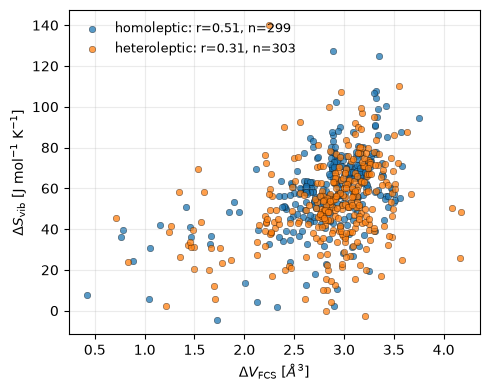

In [7]:
scatter_by_group(rows, 'dFCS_CH', target='dSvib', feature_labels=feature_labels, target_labels=target_labels)
plt.show()


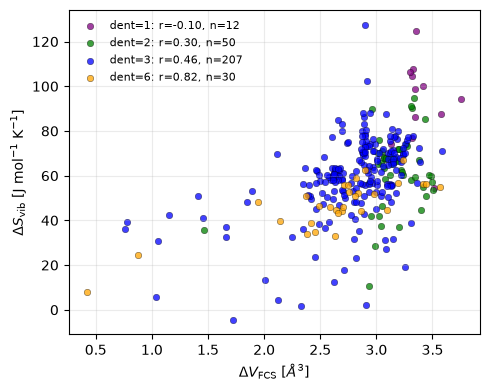

In [8]:
scatter_by_denticity(rows, 'dFCS_CH', target='dSvib', feature_labels=feature_labels, target_labels=target_labels)
plt.show()


## HS-LS Difference Descriptors

Because several thermodynamic properties are HS-LS differences, this section focuses on paired structural changes: `HS - LS`, absolute changes, and the relative first-coordination-sphere (FCS) convex-hull volume change. The FCS descriptor measures local coordination-sphere expansion without introducing the conformational sensitivity of a whole-molecule convex hull.


In [9]:
difference_features = [
    'dFeN', 'abs_dFeN',
    'dSigma', 'abs_dSigma',
    'dCShM', 'abs_dCShM',
    'dFCS_CH', 'abs_dFCS_CH', 'rel_dFCS_CH',
]

all_difference_tables = []
for target in targets:
    for label, subset in group_subsets:
        all_difference_tables.extend(correlation_table(subset, label, target=target, feature_list=difference_features)[:9])

print_correlation_table(all_difference_tables)


target   group          feature               r     n
---------------------------------------------------------
dHelec   overall        rel_dFCS_CH       0.082   602
dHelec   overall        dSigma         -0.057   602
dHelec   overall        abs_dSigma     -0.050   602
dHelec   overall        dFeN             -0.012   602
dHelec   overall        abs_dFeN         -0.012   602
dHelec   overall        dFCS_CH           0.004   602
dHelec   overall        abs_dFCS_CH       0.004   602
dHelec   overall        abs_dCShM        -0.003   602
dHelec   overall        dCShM            -0.002   602
dHelec   homoleptic     rel_dFCS_CH       0.371   299
dHelec   homoleptic     dFeN              0.282   299
dHelec   homoleptic     abs_dFeN          0.282   299
dHelec   homoleptic     dFCS_CH           0.245   299
dHelec   homoleptic     abs_dFCS_CH       0.245   299
dHelec   homoleptic     abs_dSigma      0.097   299
dHelec   homoleptic     dSigma          0.085   299
dHelec   homoleptic     dCShM   

In [10]:
difference_by_denticity = []
for target in targets:
    for denticity in sorted_denticities(rows):
        subset = [row for row in rows if row['denticity'] == denticity]
        difference_by_denticity.extend(correlation_table(subset, f'dent={denticity}', target=target, feature_list=difference_features)[:5])

print_correlation_table(difference_by_denticity)


target   group          feature               r     n
---------------------------------------------------------
dHelec   dent=1         dSigma         -0.854    12
dHelec   dent=1         abs_dSigma      0.847    12
dHelec   dent=1         dCShM            -0.818    12
dHelec   dent=1         abs_dCShM         0.699    12
dHelec   dent=1         dFCS_CH          -0.258    12
dHelec   dent=2         rel_dFCS_CH       0.221    50
dHelec   dent=2         dFeN              0.164    50
dHelec   dent=2         abs_dFeN          0.164    50
dHelec   dent=2         dCShM             0.119    50
dHelec   dent=2         abs_dCShM         0.119    50
dHelec   dent=3         rel_dFCS_CH       0.350   207
dHelec   dent=3         dFCS_CH           0.229   207
dHelec   dent=3         abs_dFCS_CH       0.229   207
dHelec   dent=3         dFeN              0.223   207
dHelec   dent=3         abs_dFeN          0.223   207
dHelec   dent=6         dFeN              0.645    30
dHelec   dent=6         abs_

## Focus On CShM And FCS Volume Differences

The global Pearson correlations should be treated as exploratory descriptors, not as predictive models. These plots focus on HS-LS differences with direct structural meaning: changes in CShM and in the convex-hull volume of the first coordination sphere.


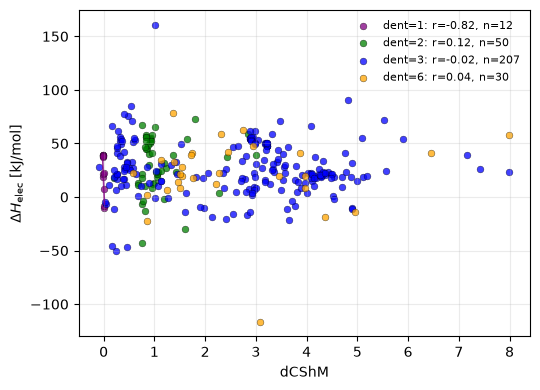

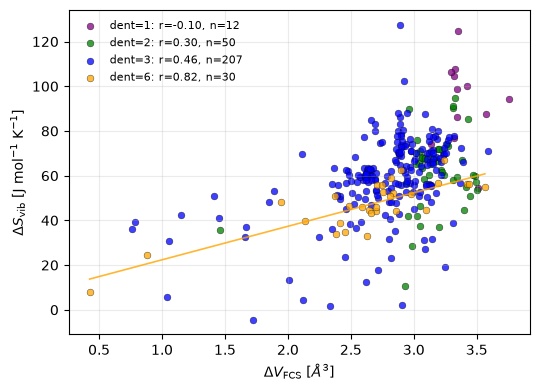

In [11]:
scatter_feature_by_denticity(rows, 'dCShM', target='dHelec', feature_labels=feature_labels, target_labels=target_labels)
plt.show()
scatter_feature_by_denticity(rows, 'dFCS_CH', target='dSvib', feature_labels=feature_labels, target_labels=target_labels)
plt.show()


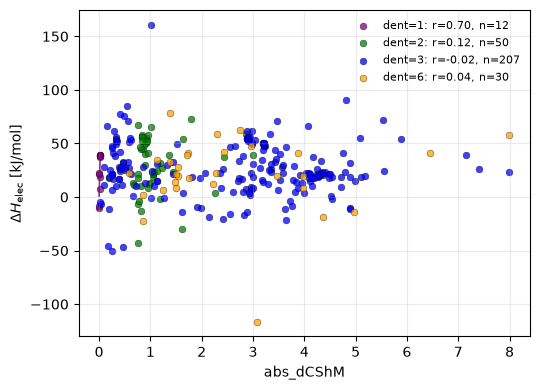

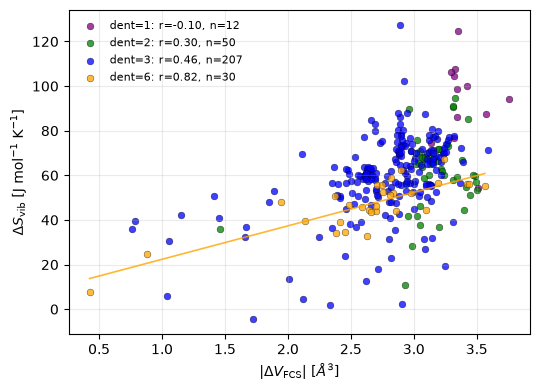

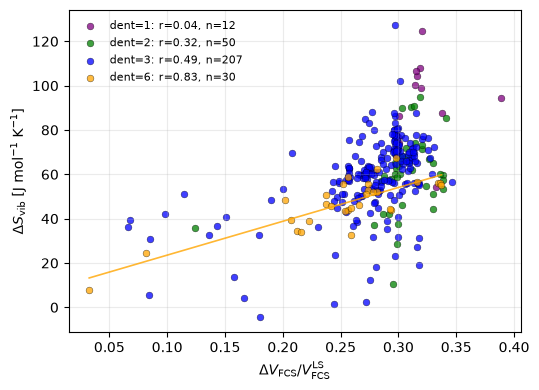

In [12]:
for feature, target in [('abs_dCShM', 'dHelec'), ('abs_dFCS_CH', 'dSvib'), ('rel_dFCS_CH', 'dSvib')]:
    scatter_feature_by_denticity(rows, feature, target=target, feature_labels=feature_labels, target_labels=target_labels)
    plt.show()


In [13]:
for feature in ['dCShM', 'abs_dCShM', 'dFCS_CH', 'abs_dFCS_CH', 'rel_dFCS_CH']:
    print()
    print(feature)
    feature_table = []
    for target in targets:
        for label, subset in group_subsets:
            r, n = pearson_correlation(subset, feature, target=target)
            if r is not None:
                feature_table.append({'group': label, 'target': target, 'feature': feature, 'r': r, 'abs_r': abs(r), 'n': n})
        for denticity in sorted_denticities(rows):
            subset = [row for row in rows if row['denticity'] == denticity]
            r, n = pearson_correlation(subset, feature, target=target)
            if r is not None:
                feature_table.append({'group': f'dent={denticity}', 'target': target, 'feature': feature, 'r': r, 'abs_r': abs(r), 'n': n})
    print_correlation_table(feature_table)



dCShM
target   group          feature               r     n
---------------------------------------------------------
dHelec   overall        dCShM            -0.002   602
dHelec   homoleptic     dCShM            -0.020   299
dHelec   heteroleptic   dCShM            -0.217   303
dHelec   dent=1         dCShM            -0.818    12
dHelec   dent=2         dCShM             0.119    50
dHelec   dent=3         dCShM            -0.023   207
dHelec   dent=6         dCShM             0.043    30
dHvib    overall        dCShM             0.398   602
dHvib    homoleptic     dCShM             0.392   299
dHvib    heteroleptic   dCShM             0.314   303
dHvib    dent=1         dCShM             0.558    12
dHvib    dent=2         dCShM             0.002    50
dHvib    dent=3         dCShM             0.501   207
dHvib    dent=6         dCShM             0.022    30
dSvib    overall        dCShM            -0.089   602
dSvib    homoleptic     dCShM            -0.250   299
dSvib    heterole

## Export Correlation Tables

In [14]:
correlation_rows = []
for section, table in [
    ('all_descriptors_grouped', summary_tables),
    ('all_descriptors_by_denticity', by_denticity),
    ('difference_descriptors_grouped', all_difference_tables),
    ('difference_descriptors_by_denticity', difference_by_denticity),
]:
    for row in table:
        correlation_rows.append({
            'Analysis Section': section,
            'Complex Subset': row['group'],
            'thermodynamic term': row['target'],
            'structural parameter': row['feature'],
            'Pearson Correlation': f"{row['r']:.2f}",
            'Num Entries': row['n'],
        })

with open(correlations_path, 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=['Analysis Section', 'Complex Subset', 'thermodynamic term', 'structural parameter', 'Pearson Correlation', 'Num Entries'])
    writer.writeheader()
    writer.writerows(correlation_rows)

print(correlations_path)


/Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/structure_thermo_correlations.csv


## Manuscript Figure: Discussed Structure--Thermodynamic Correlations

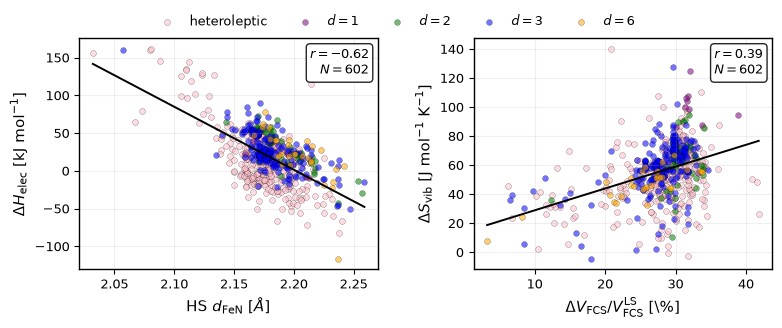

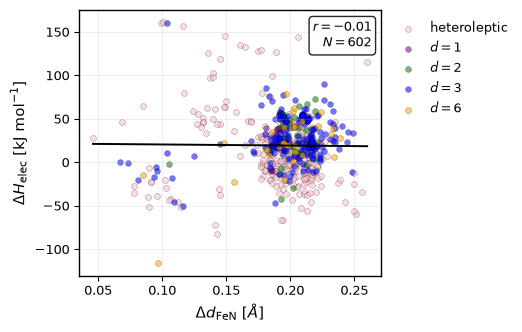

In [15]:
# Strong correlations for the main text; weaker Fe-N difference correlation for the ESI.
main_panel_specs = [
    ('HS_FeN', 'dHelec', 1.0, r'HS $d_{\mathrm{FeN}}$ [$\AA$]', r'$\Delta H_{\mathrm{elec}}$ [kJ mol$^{-1}$]'),
    ('rel_dFCS_CH', 'dSvib', 100.0, r'$\Delta V_{\mathrm{FCS}}/V_{\mathrm{FCS}}^{\mathrm{LS}}$ [\%]', r'$\Delta S_{\mathrm{vib}}$ [J mol$^{-1}$ K$^{-1}$]'),
]
esi_panel_spec = ('dFeN', 'dHelec', 1.0, r'$\Delta d_{\mathrm{FeN}}$ [$\AA$]', r'$\Delta H_{\mathrm{elec}}$ [kJ mol$^{-1}$]')

plot_groups = [
    ('heteroleptic', [row for row in rows if not row['homoleptic']], 'pink'),
    ('$d=1$', [row for row in rows if row['homoleptic'] and row['denticity'] == '1'], 'purple'),
    ('$d=2$', [row for row in rows if row['homoleptic'] and row['denticity'] == '2'], 'green'),
    ('$d=3$', [row for row in rows if row['homoleptic'] and row['denticity'] == '3'], 'blue'),
    ('$d=6$', [row for row in rows if row['homoleptic'] and row['denticity'] == '6'], 'orange'),
]

fig, axs = plt.subplots(1, 2, figsize=(7.7, 3.5))
fig.patch.set_facecolor('white')
for ax, spec in zip(axs, main_panel_specs):
    draw_correlation_panel(ax, spec, rows, plot_groups)

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.96), ncol=5, frameon=False, fontsize=9)
fig.subplots_adjust(left=0.09, right=0.99, bottom=0.20, top=0.86, wspace=0.32)
if correlations_figure_path:
    plt.savefig(correlations_figure_path, dpi=400, bbox_inches='tight', facecolor='white')
plt.show()

fig, ax = plt.subplots(figsize=(5.2, 3.5))
fig.patch.set_facecolor('white')
handles, labels = draw_correlation_panel(ax, esi_panel_spec, rows, plot_groups)
ax.legend(handles, labels, loc='upper left', bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=9)
fig.subplots_adjust(left=0.14, right=0.72, bottom=0.20, top=0.96)
if dfeN_figure_path:
    plt.savefig(dfeN_figure_path, dpi=400, bbox_inches='tight', facecolor='white')
plt.show()

**Main-text caption.** Principal structure--thermodynamic relationships identified in the dataset. Left: electronic HS--LS enthalpy difference as a function of the average HS Fe--N distance. Right: vibrational entropy change at 298 K as a function of the relative convex-hull volume change of the first coordination sphere. **ESI caption.** Electronic HS--LS enthalpy difference as a function of the HS--LS change in average Fe--N distance. In both figures, points are classified by denticity for homoleptic complexes, while heteroleptic complexes are shown separately. Black lines are least-squares fits over the complete dataset; insets report the corresponding Pearson correlation coefficient and number of systems.

## Family-Resolved Structural Fingerprints

The configuration cell assigns short chemical-motif names to these families for display, for example `bpp -- d=3, F(5,2)`. Here, `bpy` denotes a bipyridine core, and `PyBox` a pyridine-bis(oxazoline) core. The broader labels `tris(pyridyl)`, `tris(pyrazolyl)` and `pyridyl-imine` describe coordinating motifs shared by ligands with different linkers; they are not names of one unique ligand. These labels do not affect family membership, PCA coordinates or correlations.

This analysis uses only the systems assigned to the eight main $\Delta H_{\mathrm{elec}}$ distributions in notebook 5. Consequently, the structural fingerprints refer to exactly the same 119 systems used to define the family electronic baselines and widths.


In [16]:

family_membership_rows = read_csv(family_membership_path)
family_statistics_rows = read_csv(family_statistics_path)
family_structural_rows, family_structural_statistics = build_family_structural_data(
    rows, family_membership_rows, family_statistics_rows, motif_names=family_motif_names
)

num_main_members = sum(
    str(row['Main Distribution']).strip().lower() == 'true'
    for row in family_membership_rows
)
assert len(family_structural_rows) == num_main_members, 'Missing structural data for accepted family members'

family_structural_statistics = rounded_rows(
    family_structural_statistics,
    {column: 3 for column in family_structural_statistics[0] if column not in {'Denticity', 'Family', 'Chemical Motif', 'Num Main-Distribution Entries'}},
)
write_csv_rows(family_structural_statistics_path, family_structural_statistics)

print(f'Main-distribution systems with structural data: {len(family_structural_rows)}')
print(f'Family structural statistics saved to: {family_structural_statistics_path}')
family_structural_statistics


Main-distribution systems with structural data: 119
Family structural statistics saved to: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/ligand_family_structural_statistics.csv


[{'Denticity': 2,
  'Family': 'F(3,1)',
  'Num Main-Distribution Entries': 7,
  'dHelec Base [kJ/mol]': 55.37,
  'dHelec Width [kJ/mol]': 5.51,
  'HS dFeN Median [Angstrom]': 2.172,
  'HS dFeN IQR [Angstrom]': 0.003,
  'HS Sigma Median [deg]': 84.163,
  'HS Sigma IQR [deg]': 1.835,
  'LS dFeN Median [Angstrom]': 1.978,
  'LS dFeN IQR [Angstrom]': 0.001,
  'LS Sigma Median [deg]': 59.23,
  'LS Sigma IQR [deg]': 0.485},
 {'Denticity': 2,
  'Family': 'F(4,1)',
  'Num Main-Distribution Entries': 11,
  'dHelec Base [kJ/mol]': 21.19,
  'dHelec Width [kJ/mol]': 27.04,
  'HS dFeN Median [Angstrom]': 2.204,
  'HS dFeN IQR [Angstrom]': 0.008,
  'HS Sigma Median [deg]': 83.843,
  'HS Sigma IQR [deg]': 11.434,
  'LS dFeN Median [Angstrom]': 1.996,
  'LS dFeN IQR [Angstrom]': 0.013,
  'LS Sigma Median [deg]': 52.996,
  'LS Sigma IQR [deg]': 7.064},
 {'Denticity': 3,
  'Family': 'F(1,5)',
  'Num Main-Distribution Entries': 8,
  'dHelec Base [kJ/mol]': 6.75,
  'dHelec Width [kJ/mol]': 12.73,
  'HS dF

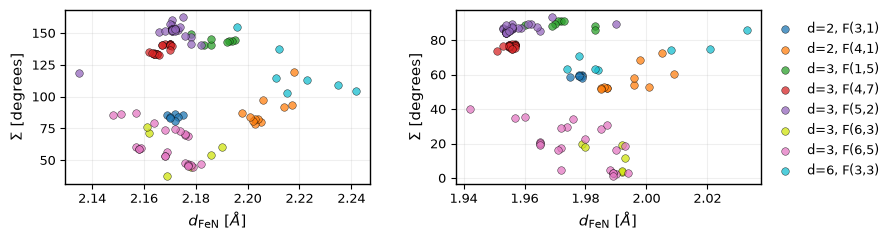

In [17]:
family_order = list(dict.fromkeys(row['Family Label'] for row in family_structural_rows))
family_colors = dict(zip(family_order, [
    '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728',
    '#9467bd', "#cfe40d", '#e377c2', '#17becf',
]))

fig, axs = plt.subplots(1, 2, figsize=(9.4, 3.0))
panel_specs = [
    ('HS_FeN', 'HS_Sigma'),
    ('LS_FeN', 'LS_Sigma'),
]

for ax, (x_parameter, y_parameter) in zip(axs, panel_specs):
    for family in family_order:
        family_rows = [row for row in family_structural_rows if row['Family Label'] == family]
        color = family_colors[family]
        ax.scatter(
            [row[x_parameter] for row in family_rows],
            [row[y_parameter] for row in family_rows],
            s=30, color=color, edgecolor='black', linewidth=0.35, alpha=0.75,
            label=family if ax is axs[0] else None,
        )
    ax.set_xlabel(r'$d_{\mathrm{FeN}}$ [$\AA$]', fontsize=11)
    ax.set_ylabel(r'$\Sigma$ [degrees]', fontsize=11)
    ax.tick_params(axis='both', direction='out', labelsize=9)
    ax.grid(alpha=0.20)
    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.0)

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center left', bbox_to_anchor=(0.82, 0.5), frameon=False, fontsize=9)
fig.subplots_adjust(left=0.08, right=0.82, bottom=0.22, top=0.80, wspace=0.28)

if family_structural_png_path:
    plt.savefig(family_structural_png_path, dpi=400, bbox_inches='tight', facecolor='white')
if family_structural_pdf_path:
    plt.savefig(family_structural_pdf_path, bbox_inches='tight', facecolor='white')
plt.show()


**Caption.** Family-resolved structural spaces of the HS and LS minima for the 119 systems assigned to the eight main $\Delta H_{\mathrm{elec}}$ distributions. Colors identify ligand families across both panels, and individual systems are shown as circles. Only systems used to define $\Delta H_{\mathrm{elec}}^{base}$ and $\Delta H_{\mathrm{elec}}^{width}$ are included.


## Strong Correlations: Configurable Selection

Collect structural--thermodynamic correlations using the absolute Pearson and sample-size thresholds below, including negative correlations. Set `group_filter = None` to include all groups, a name such as `'homoleptic'` for one group, or a list such as `['overall', 'dent=3']` for several. Available groups are `overall`, `homoleptic`, `heteroleptic`, `dent=1`, `dent=2`, `dent=3` and `dent=6`. The full feature list is evaluated without the top-result limits used above. Selection uses unrounded coefficients; the CSV reports two decimal places. No additional system filtering is applied. Running this cell also updates the Table S4 LaTeX file and its companion ESI CSV directly, using the same thresholds and group filter but omitting absolute-change descriptors.


In [28]:
min_abs_pearson = 0.75
min_entries     = 1 
group_filter    = None # All groups; or e.g. 'homoleptic' or ['overall', 'dent=3'].

correlation_subsets = list(group_subsets)
for denticity in sorted_denticities(rows):
    subset = [row for row in rows if row['homoleptic'] and row['denticity'] == denticity]
    correlation_subsets.append((f'dent={denticity}', subset))

if group_filter is not None:
    selected_groups = [group_filter] if isinstance(group_filter, str) else list(group_filter)
    available_groups = {label for label, subset in correlation_subsets}
    unknown_groups = set(selected_groups) - available_groups
    if unknown_groups:
        raise ValueError(f'Unknown groups: {sorted(unknown_groups)}. Available groups: {sorted(available_groups)}')
    correlation_subsets = [(label, subset) for label, subset in correlation_subsets if label in selected_groups]

print('Groups included:', [label for label, subset in correlation_subsets])

strong_correlations = []
for label, subset in correlation_subsets:
    for target in targets:
        table = correlation_table(subset, label, target=target, feature_list=features)
        for result in table:
            if abs(result['r']) > min_abs_pearson and result['n'] > min_entries:
                strong_correlations.append(result)

strong_correlations.sort(key=lambda result: abs(result['r']), reverse=True)
print_correlation_table(strong_correlations)

strong_correlation_rows = []
for result in strong_correlations:
    strong_correlation_rows.append({
        'Complex Subset': result['group'],
        'thermodynamic term': result['target'],
        'structural parameter': result['feature'],
        'Pearson Correlation': f"{result['r']:.2f}",
        'Num Entries': result['n'],
    })

write_csv_rows(strong_correlations_path, strong_correlation_rows, fieldnames=[
    'Complex Subset', 'thermodynamic term', 'structural parameter',
    'Pearson Correlation', 'Num Entries',
])
print(f'Collected {len(strong_correlations)} correlations with |r| > {min_abs_pearson} and N > {min_entries}.')
print(f'Saved to: {strong_correlations_path}')

esi_correlations = [result for result in strong_correlations if not result['feature'].startswith('abs_')]
esi_correlations.sort(key=lambda result: (targets.index(result['target']), -abs(result['r'])))
esi_correlation_rows = []
for result in esi_correlations:
    esi_correlation_rows.append({
        'Complex Subset': result['group'],
        'thermodynamic term': result['target'],
        'structural parameter': result['feature'],
        'Pearson Correlation': f"{result['r']:.3f}",
        'Num Entries': result['n'],
    })

write_csv_rows(esi_correlations_path, esi_correlation_rows, fieldnames=[
    'Complex Subset', 'thermodynamic term', 'structural parameter',
    'Pearson Correlation', 'Num Entries',
])
write_strong_structural_correlations_table(
    esi_correlations, esi_correlations_table_path, min_abs_pearson=min_abs_pearson
)
print(f'Table S4 updated: {esi_correlations_table_path}')
print(f'ESI correlations: {esi_correlations_path}')


Groups included: ['overall', 'homoleptic', 'heteroleptic', 'dent=1', 'dent=2', 'dent=3', 'dent=6']
target   group          feature               r     n
---------------------------------------------------------
dHvib    dent=1         dFeN              0.897    12
dHvib    dent=1         abs_dFeN          0.897    12
dHvib    dent=1         rel_dFCS_CH       0.895    12
dGtot    dent=2         HS_FeN           -0.855    50
dHelec   dent=1         dEpsylon         -0.854    12
dHvib    dent=1         dFCS_CH           0.852    12
dHvib    dent=1         abs_dFCS_CH       0.852    12
dHelec   dent=1         abs_dEpsylon      0.847    12
dHelec   dent=2         HS_FeN           -0.839    50
dGtot    dent=6         LS_FeN           -0.834    30
dHelec   dent=6         LS_FeN           -0.830    30
dSvib    dent=6         rel_dFCS_CH       0.827    30
dSvib    dent=6         dFCS_CH           0.821    30
dSvib    dent=6         abs_dFCS_CH       0.821    30
dHelec   dent=1         dCShM    

## Ligand Families In The Full Structural Descriptor Space

Project the same 119 main-distribution members of the eight selected families into two dimensions, fitting HS and LS separately. Each state is described by its average Fe-N distance, Sigma distortion, CShM and FCS convex-hull volume. These are the four state-specific structural descriptors retained in the correlation analysis; whole-molecule hull volumes and HS-LS differences are not included.

Before PCA, each descriptor is centred and divided by its standard deviation across the selected systems, separately for HS and LS. Family labels are used only for colouring, not for fitting the projections. No jitter, artificial separation or additional system filtering is applied. Nearby points therefore have similar standardized structural descriptors to the extent retained by the two principal components. HS and LS axes are fitted independently, so their coordinates should not be interpreted as a spin-transition displacement.

The axes report the fraction of structural variance retained by each component. Overlap in two dimensions does not rule out separation in omitted components, and clusters here apply only to these selected main-distribution members, not necessarily to every member of a family. Coordinates, component coefficients and scaling parameters are exported for inspection.


HS: 119 systems; PC1 = 72.6%, PC2 = 26.4%; total variance retained = 99.0%
LS: 119 systems; PC1 = 80.7%, PC2 = 17.8%; total variance retained = 98.5%
PCA coordinates: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/ligand_family_structural_pca.csv
PCA coefficients and scaling: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/ligand_family_structural_pca_loadings.csv


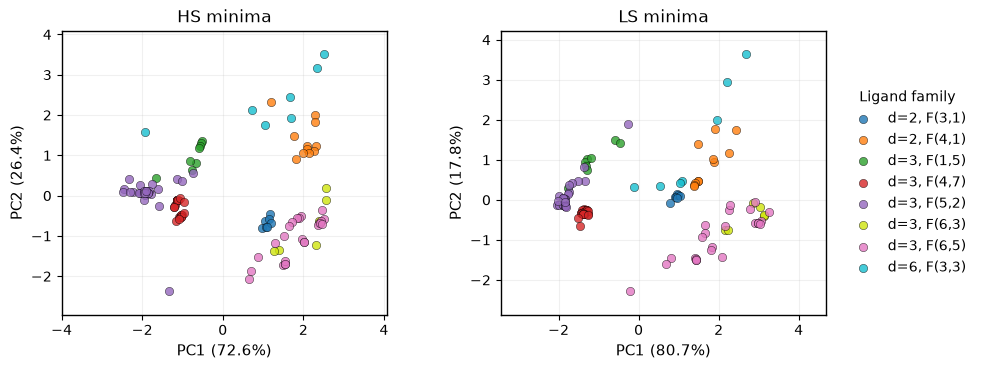

In [23]:
structural_pca_parameters = ['FeN', 'Sigma', 'CShM', 'FCS_CH']

pca_coordinates, pca_loadings, pca_variance = build_family_structural_pca(
    rows, family_structural_rows, structural_pca_parameters
)

for state in ['HS', 'LS']:
    variance = pca_variance[state]
    print(f'{state}: {len(family_structural_rows)} systems; '
          f'PC1 = {100 * variance[0]:.1f}%, PC2 = {100 * variance[1]:.1f}%; '
          f'total variance retained = {100 * sum(variance):.1f}%')

write_csv_rows(family_structural_pca_path, pca_coordinates)
write_csv_rows(family_structural_loadings_path, pca_loadings)
print(f'PCA coordinates: {family_structural_pca_path}')
print(f'PCA coefficients and scaling: {family_structural_loadings_path}')

fig, axs = plot_family_structural_pca(
    pca_coordinates, pca_variance, family_colors,
    figure_path=family_structural_pca_figure_path,
)
plt.show()


**Caption.** Independent PCA projections of the HS (left) and LS (right) minima for the same 119 systems in the eight selected ligand-family main distributions. Each projection combines standardized Fe-N distance, Sigma, CShM and FCS convex-hull volume. Colours identify ligand families and percentages give the variance explained by each axis. Family labels do not influence the PCA. These maps explore structural clustering within the previously selected electronic main distributions.


## ESI Table: Strong Nonredundant Structural Correlations

Table S4 is generated directly by the configurable correlation-selection cell above. Re-run that cell after changing `min_abs_pearson`, `min_entries` or `group_filter`; there is no separate ESI threshold. The table uses signed HS-LS changes rather than their absolute values. Small subsets require particular caution. Selection uses unrounded coefficients, and the LaTeX table reports three decimals so values just above the threshold remain distinguishable. The cell below only displays the current ESI selection and does not overwrite it.


In [ ]:
print_correlation_table(esi_correlations)


## Structure--Thermodynamic Correlations Within Ligand Families

Bridge the family-resolved structural PCA and the dataset-wide correlations by examining each of the same eight families separately. Only the same 119 main-distribution systems are used; no additional outliers are removed. All thermodynamic targets and structural descriptors are tested, using signed rather than absolute HS-LS changes.

The CSV retains every tested pair and its actual paired sample size, including an empty Pearson field when fewer than three paired values or a constant variable prevent its calculation. The displayed and ESI summary focuses on the three relationships discussed in the manuscript. These within-family correlations describe local variation in the selected electronic main distributions, unlike the earlier correlations spanning the full chemical and thermodynamic range of the 602 retained systems. The family subsets are small and were selected using electronic energies, so neither weak nor strong local correlations should be treated as universal design rules.


In [ ]:
family_correlation_features = [feature for feature in features if not feature.startswith('abs_')]
family_correlations = build_family_structure_thermo_correlations(
    rows, family_structural_rows, targets, family_correlation_features
)

family_correlation_rows = []
for result in family_correlations:
    family_correlation_rows.append({
        'Denticity': result['denticity'],
        'Family': result['family'],
        'Chemical Motif': result['motif'],
        'Num Main-Distribution Entries': result['family_n'],
        'thermodynamic term': result['target'],
        'structural parameter': result['feature'],
        'Pearson Correlation': '' if result['r'] is None else f"{result['r']:.6f}",
        'Num Entries': result['n'],
    })

write_csv_rows(family_correlations_path, family_correlation_rows)
write_family_structural_correlations_table(family_correlations, family_correlations_table_path)

discussed_relationships = [('HS_FeN', 'dHelec'), ('dFeN', 'dHvib'), ('rel_dFCS_CH', 'dSvib')]
family_correlation_summary = []
for result in family_correlations:
    if (result['feature'], result['target']) in discussed_relationships:
        family_correlation_summary.append(result)
print_correlation_table(family_correlation_summary)
print(f'All within-family correlations: {family_correlations_path}')
print(f'ESI summary table: {family_correlations_table_path}')
